In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

## Section 1: Why Attention Is Not Enough
Attention allows tokens to communicate.
We still need a mechanism to transform information.
We still need stable training.

## Section 2: Layer Normalization
Implement normalization manually

In [2]:
x = torch.tensor([
    [1.0, 2.0, 3.0],
    [5.0, 10.0, 15.0],
])

eps = 1e-5

mean = x.mean(dim=-1, keepdim=True)
variance = x.var(dim=-1, keepdim=True, unbiased=False)

normalized_output = (x - mean) / torch.sqrt(variance + eps)

normalized_output

tensor([[-1.2247,  0.0000,  1.2247],
        [-1.2247,  0.0000,  1.2247]])

In [3]:
# Verify with
normalized_output.mean(dim=-1)
normalized_output.var(dim=-1, unbiased=False)

tensor([1.0000, 1.0000])

## Section 3: Exploring GELU
Compare ReLU and GELU

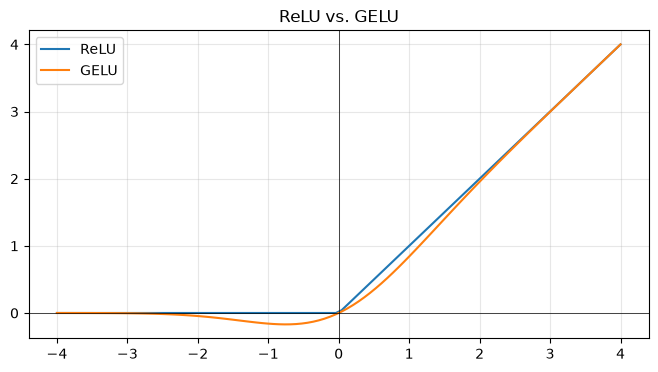

In [4]:
values = torch.linspace(-4, 4, 100)

relu_values = F.relu(values)
gelu_values = F.gelu(values)

plt.figure(figsize=(8, 4))
plt.plot(values.numpy(), relu_values.numpy(), label="ReLU")
plt.plot(values.numpy(), gelu_values.numpy(), label="GELU")
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.title("ReLU vs. GELU")
plt.show()

## Section 4: Feed Forward Network
Review figure 4.10 in the book

In [5]:
input_shape = (2, 3, 768)
x_ffn = torch.randn(input_shape)

ffn = nn.Sequential(
    nn.Linear(768, 3072),
    nn.GELU(),
    nn.Linear(3072, 768),
)

output_ffn = ffn(x_ffn)

print("Input shape: ", x_ffn.shape)
print("Output shape:", output_ffn.shape)

Input shape:  torch.Size([2, 3, 768])
Output shape: torch.Size([2, 3, 768])


In [6]:
linear_1 = nn.Linear(768, 3072)
gelu = nn.GELU()
linear_2 = nn.Linear(3072, 768)

h = linear_1(x_ffn)
print("After first linear:", h.shape)  # (2, 3, 3072)

h = gelu(h)
print("After GELU:", h.shape)          # (2, 3, 3072)

h = linear_2(h)
print("After second linear:", h.shape) # (2, 3, 768)


After first linear: torch.Size([2, 3, 3072])
After GELU: torch.Size([2, 3, 3072])
After second linear: torch.Size([2, 3, 768])


## Section 5: Residual Connections
Inspect output shapes using a toy network
Compare
 - With residual
 - Without residual

In [7]:
torch.manual_seed(0)

x_residual = torch.randn(2, 3, 8)
layer = nn.Sequential(
    nn.Linear(8, 8),
    nn.GELU(),
    nn.Linear(8, 8),
)

without_residual = layer(x_residual)
with_residual = x_residual + without_residual

print("Input:            ", x_residual.shape)
print("Without residual: ", without_residual.shape)
print("With residual:    ", with_residual.shape)

Input:             torch.Size([2, 3, 8])
Without residual:  torch.Size([2, 3, 8])
With residual:     torch.Size([2, 3, 8])


## Section 6: Connecting Everything
This notebook has walked you through the following process, which is the blueprint for a TransformerBlock
 - Input
 - LayerNorm
 - Attention
 - Add Residual
 - LayerNorm
 - FeedForward
 - Add Residual
 - Output